In [27]:
import pandas as pd
from systems_final_project.data.config import GAUGES, USGS_DIR
# checking the gauge locations and USGS points 
print(USGS_DIR)
print(GAUGES)

/home/shobs/Desktop/CMU/SEM 1/Systems/finalproject_repo/Systems_final_project/data/raw/usgs
{'point': '03085152', 'braddock': '03085000', 'elizabeth': '03075070', 'sutersville': '03083500', 'natrona': '03049500', 'kittanning': '03036500'}


In [28]:
sorted(p.name for p in (USGS_DIR / "point").glob("*.parquet"))
# checking which years data we have 

['WY2016.parquet',
 'WY2017.parquet',
 'WY2018.parquet',
 'WY2019.parquet',
 'WY2020.parquet',
 'WY2021.parquet',
 'WY2022.parquet',
 'WY2023.parquet',
 'WY2024.parquet',
 'WY2025.parquet',
 'WY2026.parquet',
 'WY2027.parquet']

In [29]:
# reading one year's data to see what exactly it has 
df = pd.read_parquet(USGS_DIR / "point" / "WY2024.parquet")
df


,time,value,approval_status,qualifier
0,2023-10-01 00:00:00+00:00,16.65,Approved,<NA>
1,2023-10-01 00:05:00+00:00,16.68,Approved,<NA>
2,2023-10-01 00:10:00+00:00,16.65,Approved,<NA>
3,2023-10-01 00:15:00+00:00,16.64,Approved,<NA>
4,2023-10-01 00:20:00+00:00,16.63,Approved,<NA>
...,...,...,...,...
104177,2024-09-30 23:40:00+00:00,17.30,Approved,<NA>
104178,2024-09-30 23:45:00+00:00,17.29,Approved,<NA>
104179,2024-09-30 23:50:00+00:00,17.31,Approved,<NA>
104180,2024-09-30 23:55:00+00:00,17.31,Approved,<NA>


In [30]:
df.info()
# the data type of time is datetime us UTC, so this means that there are no pronlems with time zones. The data is in UTC, which is good.

<class 'pandas.DataFrame'>
RangeIndex: 104182 entries, 0 to 104181
Data columns (total 4 columns):
 #   Column           Non-Null Count   Dtype              
---  ------           --------------   -----              
 0   time             104182 non-null  datetime64[us, UTC]
 1   value            104182 non-null  float64            
 2   approval_status  104182 non-null  str                
 3   qualifier        0 non-null       string             
dtypes: datetime64[us, UTC](1), float64(1), str(1), string(1)
memory usage: 4.0 MB


In [31]:
# next we are combining all the files for a gauge, so all years in one df 

files = sorted((USGS_DIR / "point").glob("*.parquet"))
point = pd.concat([pd.read_parquet(f) for f in files], ignore_index=True)

print(len(point), "rows")
print(point.time.min(), "->", point.time.max())

# from october 1 2015 to nov 9 2026

1074862 rows
2015-10-01 05:00:00+00:00 -> 2026-11-09 00:00:00+00:00


In [32]:
# doing the same for all the gauges ,
frames = []
for name in GAUGES:
    files = sorted((USGS_DIR / name).glob("*.parquet"))
    df = pd.concat([pd.read_parquet(f) for f in files], ignore_index=True)
    df["gauge"] = name          # label each row with its gauge
    frames.append(df)

gauges = pd.concat(frames, ignore_index=True)
gauges = gauges.sort_values(["gauge", "time"]).reset_index(drop=True)
gauges

# now we have all the data in a single dataframe , this is all gauge data, rainfall not touched yet  

,time,value,approval_status,qualifier,gauge
0,2015-10-01 05:00:00+00:00,12.28,Approved,<NA>,braddock
1,2015-10-01 05:15:00+00:00,12.29,Approved,<NA>,braddock
2,2015-10-01 05:30:00+00:00,12.29,Approved,<NA>,braddock
3,2015-10-01 05:45:00+00:00,12.29,Approved,<NA>,braddock
4,2015-10-01 06:00:00+00:00,12.29,Approved,<NA>,braddock
...,...,...,...,...,...
3001818,2026-11-08 23:00:00+00:00,4.22,Provisional,<NA>,sutersville
3001819,2026-11-08 23:15:00+00:00,4.22,Provisional,<NA>,sutersville
3001820,2026-11-08 23:30:00+00:00,4.22,Provisional,<NA>,sutersville
3001821,2026-11-08 23:45:00+00:00,4.22,Provisional,<NA>,sutersville


In [33]:
gauges.groupby("gauge").agg(
    rows=("time", "size"),
    start=("time", "min"),
    end=("time", "max"),
    min_ft=("value", "min"),
    median_ft=("value", "median"),
    max_ft=("value", "max"),
)
# checking min, median and max values for each gauge, to see if there are any outliers or problems with the data., the point has much more rows than the other ones, this is because it started reported values at 5 min intervals 

,rows,start,end,min_ft,median_ft,max_ft
gauge,,,,,,
braddock,386780,2015-10-01 05:00:00+00:00,2026-11-09 00:00:00+00:00,10.80,12.20,24.43
elizabeth,388548,2015-10-01 00:00:00+00:00,2026-11-09 00:00:00+00:00,6.06,10.85,24.54
kittanning,380721,2015-10-01 00:00:00+00:00,2026-11-09 00:00:00+00:00,9.60,11.44,21.18
natrona,383907,2015-10-01 00:00:00+00:00,2026-11-09 00:00:00+00:00,9.89,11.85,20.86
point,1074862,2015-10-01 05:00:00+00:00,2026-11-09 00:00:00+00:00,15.09,16.68,28.37
sutersville,387005,2015-10-01 00:00:00+00:00,2026-11-09 00:00:00+00:00,2.43,4.43,26.54


In [34]:
# next we check for duplicate timesteps, i.e the same gauge has multiple rows with the same timestamp, 
dup = gauges.duplicated(["gauge", "time"], keep=False)
print(dup.sum(), "rows share a timestamp with another row")
gauges[dup].head(6)

132 rows share a timestamp with another row


,time,value,approval_status,qualifier,gauge
35058,2016-10-01 00:00:00+00:00,12.25,Approved,<NA>,braddock
35059,2016-10-01 00:00:00+00:00,12.25,Approved,<NA>,braddock
70012,2017-10-01 00:00:00+00:00,12.34,Approved,<NA>,braddock
70013,2017-10-01 00:00:00+00:00,12.34,Approved,<NA>,braddock
105050,2018-10-01 00:00:00+00:00,11.66,Approved,<NA>,braddock
105051,2018-10-01 00:00:00+00:00,11.66,Approved,<NA>,braddock


In [35]:

same = gauges[dup].groupby(["gauge", "time"])["value"].nunique()
print("pairs with different values:", (same > 1).sum())
# all the duplicated ones timestamps have the same value, so we can just drop the duplicates and keep one of them.

pairs with different values: 0


In [36]:
before = len(gauges)
gauges = gauges.drop_duplicates(["gauge", "time"]).reset_index(drop=True)
print("dropped", before - len(gauges), "rows")

dropped 66 rows


In [37]:
# next we will for misisng values or gaps reported by the gauges 
gauges.groupby("gauge")["value"].apply(lambda s: s.isna().sum())

# elizabeth has a lot of NAN values, it stops reporting after june 2026, so we can drop after that 

gauge
braddock           0
elizabeth      14796
kittanning         0
natrona            0
point              0
sutersville        0
Name: value, dtype: int64

In [38]:
gauges["step"] = gauges.groupby("gauge")["time"].diff()
gauges[["gauge", "time", "value", "step"]].head(8)

,gauge,time,value,step
0,braddock,2015-10-01 05:00:00+00:00,12.28,NaT
1,braddock,2015-10-01 05:15:00+00:00,12.29,0 days 00:15:00
2,braddock,2015-10-01 05:30:00+00:00,12.29,0 days 00:15:00
3,braddock,2015-10-01 05:45:00+00:00,12.29,0 days 00:15:00
4,braddock,2015-10-01 06:00:00+00:00,12.29,0 days 00:15:00
5,braddock,2015-10-01 06:15:00+00:00,12.29,0 days 00:15:00
6,braddock,2015-10-01 06:30:00+00:00,12.29,0 days 00:15:00
7,braddock,2015-10-01 06:45:00+00:00,12.29,0 days 00:15:00


In [39]:
big = gauges[gauges.step > pd.Timedelta(hours=6)]
big = big.assign(gap_start=big.time - big.step)[["gauge", "gap_start", "time", "step"]]
big = big.rename(columns={"time": "gap_end", "step": "length"})
big.sort_values("length", ascending=False).head(50)
# these are all the gaps in the data 

,gauge,gap_start,gap_end,length
1379831,natrona,2022-02-17 23:00:00+00:00,2022-04-05 14:30:00+00:00,46 days 15:30:00
885796,kittanning,2019-01-05 02:00:00+00:00,2019-01-24 19:45:00+00:00,19 days 17:45:00
885035,kittanning,2018-12-02 19:45:00+00:00,2018-12-22 02:30:00+00:00,19 days 06:45:00
1077294,kittanning,2024-07-22 10:45:00+00:00,2024-08-05 13:00:00+00:00,14 days 02:15:00
853947,kittanning,2017-12-29 17:45:00+00:00,2018-01-12 19:30:00+00:00,14 days 01:45:00
886177,kittanning,2019-01-28 18:45:00+00:00,2019-02-07 04:45:00+00:00,9 days 10:00:00
885464,kittanning,2018-12-26 13:30:00+00:00,2019-01-01 15:15:00+00:00,6 days 01:45:00
2638896,sutersville,2016-06-15 22:45:00+00:00,2016-06-21 14:15:00+00:00,5 days 15:30:00
2719983,sutersville,2018-10-21 10:15:00+00:00,2018-10-25 15:15:00+00:00,4 days 05:00:00
360589,braddock,2026-02-04 21:30:00+00:00,2026-02-09 01:00:00+00:00,4 days 03:30:00


In [40]:
big.groupby("gauge")["length"].agg(["count", "sum", "max"])

,count,sum,max
gauge,,,
braddock,6,11 days 08:15:00,4 days 03:30:00
elizabeth,8,7 days 22:00:00,2 days 10:45:00
kittanning,10,90 days 04:15:00,19 days 17:45:00
natrona,7,54 days 06:30:00,46 days 15:30:00
point,5,3 days 07:25:00,0 days 23:35:00
sutersville,14,22 days 22:00:00,5 days 15:30:00


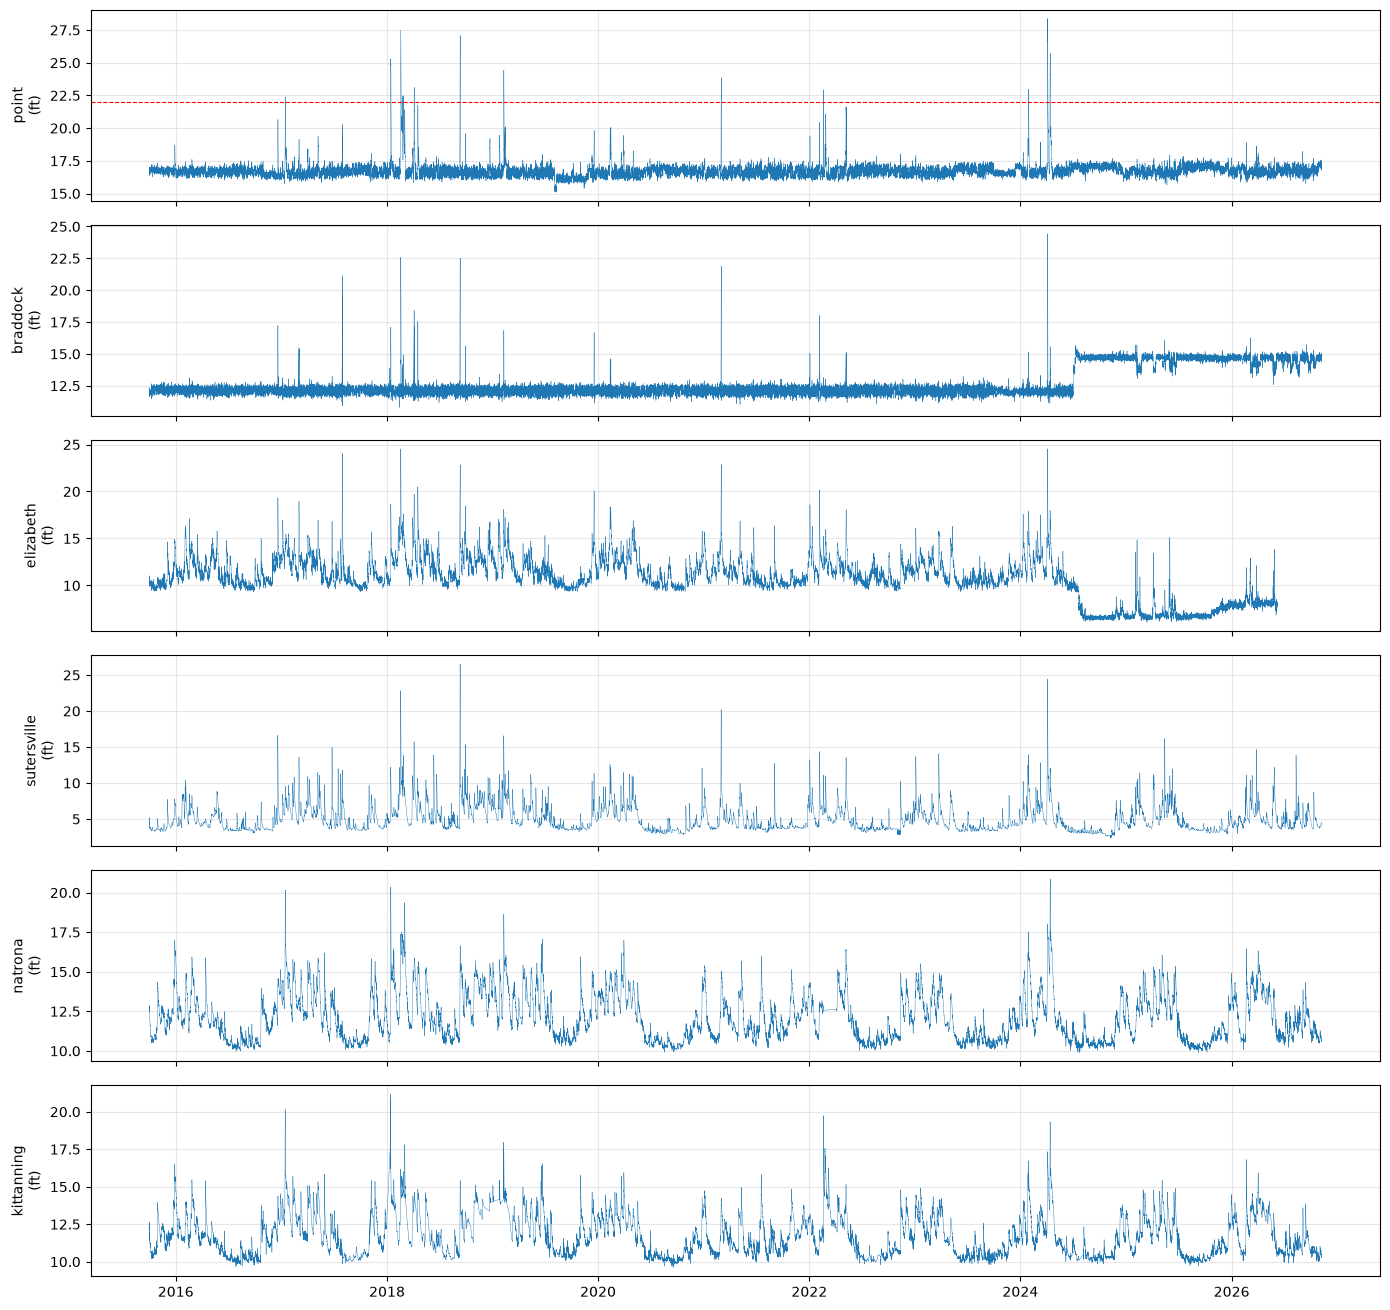

In [41]:
# we have to decide how to handle the gaps in the data, after filling in a hourly grid 
import matplotlib.pyplot as plt

names = list(GAUGES)
fig, axes = plt.subplots(len(names), 1, figsize=(14, 2.2 * len(names)), sharex=True)

for ax, name in zip(axes, names):
    d = gauges[gauges.gauge == name]
    ax.plot(d.time, d.value, lw=0.3)
    ax.set_ylabel(f"{name}\n(ft)")
    ax.grid(alpha=0.3)

axes[names.index("point")].axhline(22, color="red", ls="--", lw=0.8)  # flood threshold
plt.tight_layout()

# we see a median shift in braddock and elizabeth suddenly, this is because of a dam that was created. 

In [42]:
hourly = {}
for name in names:
    s = gauges[gauges.gauge == name].set_index("time")["value"]
    hourly[name] = s.resample("1h", label="right", closed="right").mean()

hourly = pd.DataFrame(hourly)
hourly

# resampling from 15 min intervals to hourly intervals

,point,braddock,elizabeth,sutersville,natrona,kittanning
time,,,,,,
2015-10-01 00:00:00+00:00,NaN,NaN,10.5100,3.9700,12.8700,12.4000
2015-10-01 01:00:00+00:00,NaN,NaN,10.5225,3.9575,12.8700,12.3075
2015-10-01 02:00:00+00:00,NaN,NaN,10.5425,3.9350,12.8325,12.1900
2015-10-01 03:00:00+00:00,NaN,NaN,10.5700,3.9100,12.7675,12.1025
2015-10-01 04:00:00+00:00,NaN,NaN,10.6075,3.8975,12.6950,12.0625
...,...,...,...,...,...,...
2026-11-08 20:00:00+00:00,16.883333,14.8950,NaN,4.2375,10.6800,10.4900
2026-11-08 21:00:00+00:00,16.913333,14.8700,NaN,4.2300,10.6925,10.4900
2026-11-08 22:00:00+00:00,16.965833,14.8975,NaN,4.2225,10.6975,10.4950


In [43]:
grid = pd.date_range(hourly.index.min(), hourly.index.max(), freq="1h")
hourly = hourly.reindex(grid)
hourly.index.name = "time"

print(len(hourly), "hours")
hourly.isna().sum()

# these are all the missing hours in the data, 

97369 hours


point            89
braddock        287
elizabeth      3897
sutersville     561
natrona        1315
kittanning     2174
dtype: int64

In [44]:
# if we have short gaps in the data we can fill them in with the same value as the previous hour, I'm choosing 3 hour gaps for this 
MAX_FILL_HOURS = 3

def fill_short_gaps(s, max_hours=MAX_FILL_HOURS):
    is_na = s.isna()
    run_id = (is_na != is_na.shift()).cumsum()          # number each run of NaN / not-NaN
    run_len = is_na.groupby(run_id).transform("sum")    # length of the NaN run each row is in
    short = is_na & (run_len <= max_hours)              # only rows in short gaps
    filled = s.where(~short, s.ffill())                 # repeat last known value there
    return filled, short & filled.notna()

missing_before = hourly.isna().sum()
for name in names:
    hourly[name], hourly[f"{name}_filled"] = fill_short_gaps(hourly[name])


In [45]:
pd.DataFrame({
    "missing_before": missing_before,
    "filled": hourly[[f"{n}_filled" for n in names]].sum().values,
    "missing_after": hourly[names].isna().sum(),
})

,missing_before,filled,missing_after
point,89,8,81
braddock,287,8,279
elizabeth,3897,11,3886
sutersville,561,22,539
natrona,1315,14,1301
kittanning,2174,14,2160


In [ ]:
# that doesnt fill a lot of values , the long gaps are still there 
# for those we have to check if they're during flood times 
# i am using 20 feet as the threshold for flood times 
FLOOD_FT = 20

level = hourly["point"].dropna()      # skip outage hours so a gap can't fake a crossing
above = level >= FLOOD_FT
crossings = level.index[above & ~above.shift(1, fill_value=False)]

print(f"Point went above {FLOOD_FT} ft {len(crossings)} times")
print(f"Hours spent above: {above.sum()} ({above.mean():.2%} of the time)")

# 25 times the water level went above the threshold 


Point went above 20 ft 25 times
Hours spent above: 770 (0.79% of the time)


In [ ]:
# we can fill them as NAN for now and then decide how to fill the gaps later depending on the model 
upstream = [g for g in names if g != "point"]

def complete_share(cols):
    ok = hourly[["point"] + cols].notna().all(axis=1)
    wy = hourly.index.year + (hourly.index.month >= 10)
    return ok.groupby(wy).mean().mul(100).round(1)

pd.DataFrame({
    "all_gauges_%": complete_share(upstream),
    "without_elizabeth_%": complete_share([g for g in upstream if g != "elizabeth"]),
})

# we can drop elizabeth from the model, we can also test an ablation run just to check the effect of elizabeth on the model. 

,all_gauges_%,without_elizabeth_%
time,,
2016,94.1,94.9
2017,98.4,99.2
2018,95.7,95.7
2019,84.0,84.0
2020,99.7,100.0
2021,99.8,100.0
2022,86.2,86.2
2023,99.7,99.7
2024,96.1,96.1


### Missing-data decisions
- Gaps ≤ 3 h: forward-filled and flagged (`<gauge>_filled`). Affects only 8–22 h per gauge.
- Longer gaps: left as NaN. Completeness with all gauges: 84% (WY2019, Kittanning),
  86% (WY2022, Natrona), 65% (WY2026, Elizabeth); ≥ 94% in all other years.
- Point (target) gaps: left as NaN; rows with a missing target are dropped when modelling.
  Includes the 2018-02-17 flood peak.
- Elizabeth excluded from the main model: offline since June 2026, Dam 3 removal (Jul 2024)
  changed its level, and Braddock covers the Mon downstream. Tested as an ablation.
- Gradient boosting uses NaN natively. Linear regression / ARIMAX use complete rows only.
  The main comparison scores all models on the same hours.

In [48]:
# next we are checking spike events, where the water levl suddenly jumps up and then down, this is usually a sign of a problem with the gauge, or a sudden rain event.
gauges["jump"] = gauges.groupby("gauge")["value"].diff()

gauges.groupby("gauge")["jump"].agg(
    biggest_up="max",
    biggest_down="min",
    over_1ft=lambda s: (s.abs() > 1).sum(),
    over_3ft=lambda s: (s.abs() > 3).sum(),
).round(2)

,biggest_up,biggest_down,over_1ft,over_3ft
gauge,,,,
braddock,1.80,-1.16,10,0
elizabeth,0.73,-1.10,1,0
kittanning,5.70,-0.69,2,1
natrona,0.58,-0.79,0,0
point,2.01,-2.12,2,0
sutersville,1.24,-1.25,3,0


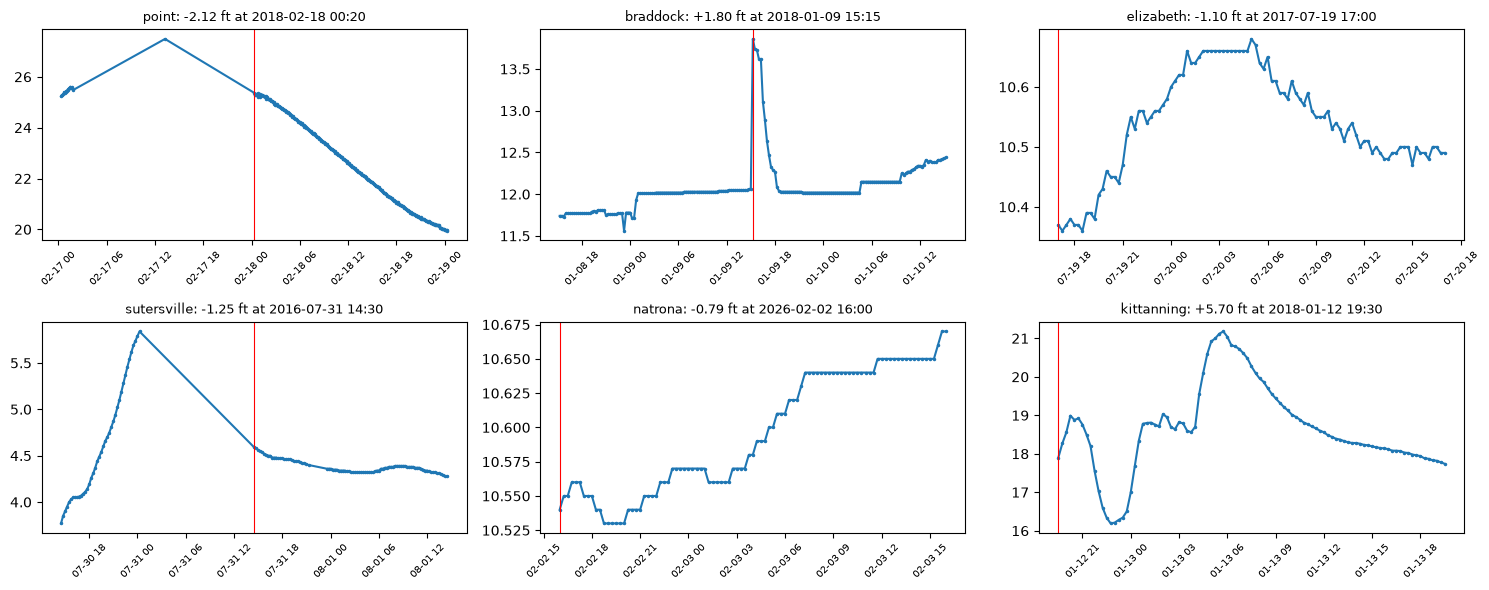

In [49]:
fig, axes = plt.subplots(2, 3, figsize=(15, 6))
for ax, name in zip(axes.flat, GAUGES):
    d = gauges[gauges.gauge == name].set_index("time")
    t = d["jump"].abs().idxmax()
    seg = d.loc[t - pd.Timedelta("1D"): t + pd.Timedelta("1D"), "value"]
    ax.plot(seg.index, seg.values, marker=".", ms=3)
    ax.axvline(t, color="red", lw=0.8)
    ax.set_title(f"{name}: {d.loc[t, 'jump']:+.2f} ft at {t:%Y-%m-%d %H:%M}", fontsize=9)
    ax.tick_params(axis="x", labelrotation=45, labelsize=7)
plt.tight_layout()

In [50]:
normal_step = gauges.step <= pd.Timedelta("30min")
gauges.loc[(gauges.jump.abs() > 1) & normal_step, ["gauge", "time", "value", "jump", "step"]]

,gauge,time,value,jump,step
73853,braddock,2017-11-10 00:30:00+00:00,11.87,-1.03,0 days 00:15:00
79672,braddock,2018-01-09 15:15:00+00:00,13.86,1.80,0 days 00:15:00
82904,braddock,2018-02-12 07:30:00+00:00,10.80,-1.06,0 days 00:15:00
88012,braddock,2018-04-06 12:30:00+00:00,12.82,1.04,0 days 00:15:00
260805,braddock,2023-03-24 23:15:00+00:00,11.65,-1.16,0 days 00:15:00
294311,braddock,2024-03-11 11:00:00+00:00,13.03,1.15,0 days 00:15:00
326104,braddock,2025-02-07 08:00:00+00:00,13.69,-1.05,0 days 00:15:00
363040,braddock,2026-03-06 13:45:00+00:00,15.21,1.08,0 days 00:15:00
363041,braddock,2026-03-06 14:00:00+00:00,16.26,1.05,0 days 00:15:00
363042,braddock,2026-03-06 14:15:00+00:00,15.22,-1.04,0 days 00:15:00


In [ ]:
# the spiking events seem to be mostly normal and we dont see any issues that are probably due to sensor problems so we  can just keep everything 


### Spikes
- Checked raw readings for sudden jumps. Only 18 jumps > 1 ft in ~3M readings; all are
  either the first reading after an outage or real rapid rises (e.g. Braddock, Jan 2018).
- No spike removal applied

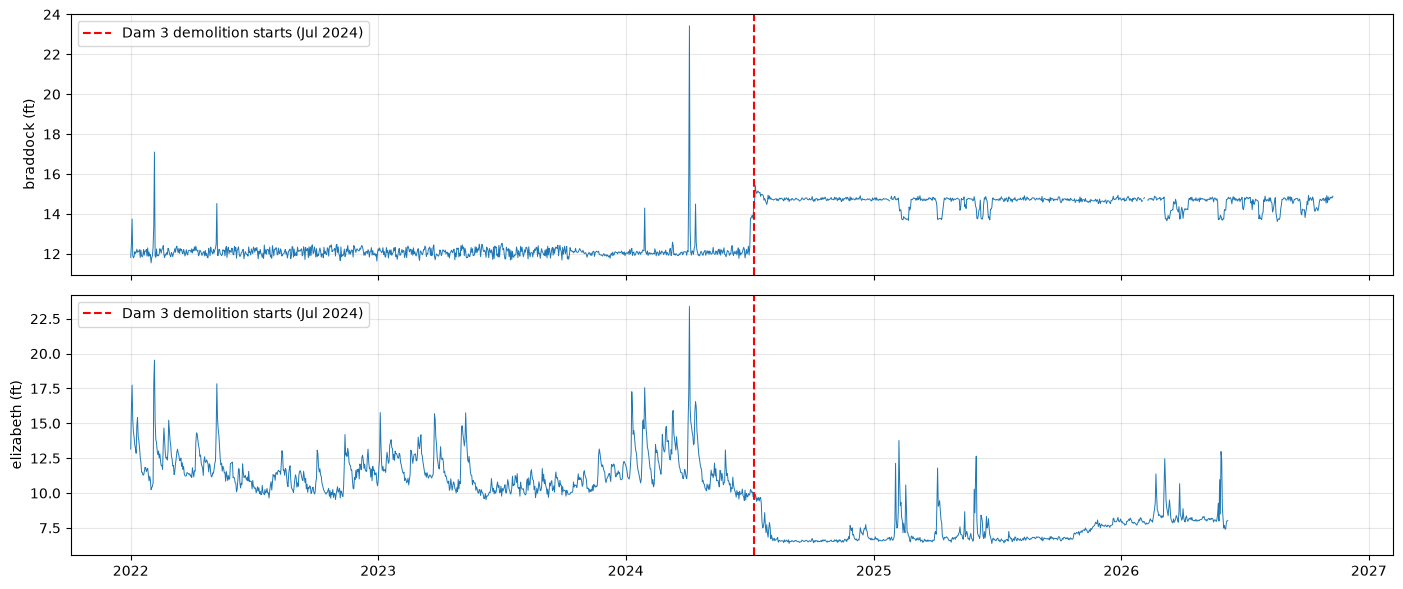

In [51]:
# next we need to add a post dam flag to the readings at braddock and elizabeth, where the median water level suddenly changes 
DAM3_DATE = pd.Timestamp("2024-07-08", tz="UTC")

fig, axes = plt.subplots(2, 1, figsize=(14, 6), sharex=True)
for ax, name in zip(axes, ["braddock", "elizabeth"]):
    daily = hourly[name].resample("D").median()["2022":]
    ax.plot(daily.index, daily.values, lw=0.7)
    ax.axvline(DAM3_DATE, color="red", ls="--", label="Dam 3 demolition starts (Jul 2024)")
    ax.set_ylabel(f"{name} (ft)")
    ax.legend(loc="upper left")
    ax.grid(alpha=0.3)
plt.tight_layout()

In [52]:
calm = hourly["point"] < hourly["point"].median()   # ignore high-water periods

pd.DataFrame({
    name: {
        "before": hourly.loc[calm & (hourly.index < DAM3_DATE), name].median(),
        "after":  hourly.loc[calm & (hourly.index >= DAM3_DATE), name].median(),
    }
    for name in GAUGES
}).T.assign(shift=lambda t: (t.after - t.before).round(2))

,before,after,shift
point,16.443333,16.501667,0.06
braddock,12.072500,14.687500,2.61
elizabeth,11.210000,7.285000,-3.93
sutersville,4.550000,4.880000,0.33
natrona,12.040000,12.635000,0.60
kittanning,11.600000,12.031250,0.43


In [53]:
hourly["post_dam3"] = hourly.index >= DAM3_DATE
hourly["post_dam3"].value_counts()

post_dam3
False    76872
True     20497
Name: count, dtype: int64

### Dam 3 removal
- Locks and Dam 3 (Elizabeth) demolition began July 2024. On calm days Braddock rose ~X ft
  and Elizabeth fell ~Y ft; other gauges changed < 0.Z ft.
- Raw levels kept. Added `post_dam3` flag. Feature engineering will use hourly changes
  (Δ level) for Braddock/Elizabeth, which are unaffected by a constant shift.

In [54]:
# next we load the rainfall data, and do the preprocessing for it, we will be using the rainfall data as a feature 
from systems_final_project.data.config import RAIN_DIR, RAIN_FCST_DIR, RAIN_LOCATIONS

rain_obs = pd.DataFrame({
    loc: pd.read_parquet(RAIN_DIR / f"{loc}.parquet").set_index("time")["precip_mm"]
    for loc in RAIN_LOCATIONS
})
rain_fcst = pd.DataFrame({
    loc: pd.read_parquet(RAIN_FCST_DIR / f"{loc}.parquet").set_index("time")["precip_fcst_24h_mm"]
    for loc in RAIN_LOCATIONS
})
rain_obs.head()

,pittsburgh,kittanning,elizabeth,sutersville
time,,,,
2015-10-01 00:00:00+00:00,0.0,0.0,0.0,0.0
2015-10-01 01:00:00+00:00,0.0,0.0,0.0,0.0
2015-10-01 02:00:00+00:00,0.0,0.0,0.0,0.0
2015-10-01 03:00:00+00:00,0.0,0.0,0.0,0.0
2015-10-01 04:00:00+00:00,0.0,0.0,0.0,0.0


In [ ]:
for name, df in [("observed", rain_obs), ("forecast", rain_fcst)]:
    valid = df.dropna(how="all")
    print(f"{name:<9} {valid.index.min()}  ->  {valid.index.max()}   missing={df.isna().sum().sum()}")
    # i am loading both obersved and forecast rainfall data 
    # there are no missing values in the observed rainfall data 
    # forecast rain data exists only after January 19 2024 

observed  2015-10-01 00:00:00+00:00  ->  2026-11-03 23:00:00+00:00   missing=0
forecast  2024-01-19 12:00:00+00:00  ->  2026-11-09 23:00:00+00:00   missing=1776


In [56]:
rain_obs.resample("D").sum().corr().round(2)

,pittsburgh,kittanning,elizabeth,sutersville
pittsburgh,1.00,0.89,0.91,0.90
kittanning,0.89,1.00,0.83,0.83
elizabeth,0.91,0.83,1.00,0.97
sutersville,0.90,0.83,0.97,1.00


In [57]:
top = rain_fcst.stack().nlargest(8).rename("forecast_mm").reset_index()
top.columns = ["time", "location", "forecast_mm"]
top["observed_mm"] = [rain_obs.at[t, loc] if t in rain_obs.index else None
                      for t, loc in zip(top.time, top.location)]
top

,time,location,forecast_mm,observed_mm
0,2026-08-02 23:00:00+00:00,pittsburgh,132.8,2.7
1,2025-04-30 00:00:00+00:00,pittsburgh,71.6,0.0
2,2026-08-20 12:00:00+00:00,elizabeth,70.2,2.2
3,2026-07-05 15:00:00+00:00,elizabeth,66.6,0.1
4,2024-08-31 19:00:00+00:00,kittanning,65.5,2.7
5,2024-07-04 22:00:00+00:00,kittanning,64.8,0.0
6,2026-08-17 01:00:00+00:00,sutersville,59.8,0.6
7,2026-07-28 19:00:00+00:00,pittsburgh,59.4,0.1


In [59]:
top = rain_fcst.stack().nlargest(8).rename("forecast_mm").reset_index()
top.columns = ["time", "location", "forecast_mm"]
top["observed_mm"] = [rain_obs.at[t, loc] if t in rain_obs.index else None
                      for t, loc in zip(top.time, top.location)]
top

,time,location,forecast_mm,observed_mm
0,2026-08-02 23:00:00+00:00,pittsburgh,132.8,2.7
1,2025-04-30 00:00:00+00:00,pittsburgh,71.6,0.0
2,2026-08-20 12:00:00+00:00,elizabeth,70.2,2.2
3,2026-07-05 15:00:00+00:00,elizabeth,66.6,0.1
4,2024-08-31 19:00:00+00:00,kittanning,65.5,2.7
5,2024-07-04 22:00:00+00:00,kittanning,64.8,0.0
6,2026-08-17 01:00:00+00:00,sutersville,59.8,0.6
7,2026-07-28 19:00:00+00:00,pittsburgh,59.4,0.1


In [58]:
FCST_CAP_MM = 50     # adjust after looking at cell 39

for loc in RAIN_LOCATIONS:
    hourly[f"rain_{loc}"] = rain_obs[loc].reindex(hourly.index)
    hourly[f"rain_fcst_{loc}"] = rain_fcst[loc].reindex(hourly.index).clip(upper=FCST_CAP_MM)

hourly["rain_basin_mean"] = hourly[[f"rain_{loc}" for loc in RAIN_LOCATIONS]].mean(axis=1)
hourly.filter(like="rain").describe().T[["count", "mean", "max"]].round(2)

,count,mean,max
rain_pittsburgh,97248.0,0.15,19.50
rain_fcst_pittsburgh,24589.0,0.13,50.00
rain_kittanning,97248.0,0.15,16.40
rain_fcst_kittanning,24589.0,0.14,50.00
rain_elizabeth,97248.0,0.15,21.50
rain_fcst_elizabeth,24589.0,0.13,50.00
rain_sutersville,97248.0,0.16,20.80
rain_fcst_sutersville,24589.0,0.13,50.00
rain_basin_mean,97248.0,0.15,12.65


In [60]:
hourly["water_year"] = hourly.index.year + (hourly.index.month >= 10)
hourly.groupby("water_year").size()

water_year
2016    8784
2017    8760
2018    8760
2019    8760
2020    8784
2021    8760
2022    8760
2023    8760
2024    8784
2025    8760
2026    8760
2027     937
dtype: int64

In [61]:
idx = hourly.index
assert idx.is_unique, "duplicate hours"
assert idx.is_monotonic_increasing, "not sorted"
assert (idx.to_series().diff().dropna() == pd.Timedelta("1h")).all(), "missing hours in the grid"
assert str(idx.tz) == "UTC", "timezone is not UTC"
assert hourly["point"].dropna().between(10, 40).all(), "Point level out of plausible range"
print("all checks passed")
print(f"{len(hourly):,} hours  {idx.min()}  ->  {idx.max()}")

all checks passed
97,369 hours  2015-10-01 00:00:00+00:00  ->  2026-11-09 00:00:00+00:00


In [62]:
pd.DataFrame({
    "dtype": hourly.dtypes.astype(str),
    "missing_%": hourly.isna().mean().mul(100).round(2),
})

,dtype,missing_%
point,float64,0.08
braddock,float64,0.29
elizabeth,float64,3.99
sutersville,float64,0.55
natrona,float64,1.34
kittanning,float64,2.22
point_filled,bool,0.00
braddock_filled,bool,0.00
elizabeth_filled,bool,0.00
sutersville_filled,bool,0.00


In [63]:
from systems_final_project.data.config import REPO_ROOT

clean_dir = REPO_ROOT / "data" / "clean"
clean_dir.mkdir(parents=True, exist_ok=True)
out = clean_dir / "hourly.parquet"

hourly.to_parquet(out)
print(f"saved {out}  ({out.stat().st_size / 1e6:.1f} MB, {hourly.shape[0]:,} rows, {hourly.shape[1]} columns)")

saved /home/shobs/Desktop/CMU/SEM 1/Systems/finalproject_repo/Systems_final_project/data/clean/hourly.parquet  (2.1 MB, 97,369 rows, 23 columns)


In [64]:
check = pd.read_parquet(out)
pd.testing.assert_frame_equal(check, hourly, check_freq=False)
print("read-back OK")

read-back OK
